# MDC_51006_EP - Foundations of Machine Learning - Lab 2

The goals of this lab are:
- to look at the variabilty of a $k$-fold cross-validation
- to use cross-validation to select a parameter
- to work with rebalanced dataset as well as custom metrics

We will reuse what we have done last week. We are going to use the same dataset as well as the same two pipelines (nearest neighbors and logistic regression).

In [ ]:
!uv pip install -U seaborn polars scikit-learn

Using Python 3.12.11 environment at: /usr
Resolved 20 packages in 114ms
Audited 20 packages in 1ms


In [ ]:
!rm german_credit_data_biased_training.csv
!wget https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv

--2025-09-26 14:08:11--  https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 689622 (673K) [text/plain]
Saving to: ‘german_credit_data_biased_training.csv’

german_credit_data_ 100%[===================>] 673.46K  --.-KB/s    in 0.02s   

2025-09-26 14:08:11 (33.8 MB/s) - ‘german_credit_data_biased_training.csv’ saved [689622/689622]



In [ ]:
import polars as pl

In [ ]:
german_credit = pl.read_csv("german_credit_data_biased_training.csv")

In [ ]:
import seaborn.objects as so

In [ ]:
import polars.selectors as cs
string_columns = german_credit.select(cs.string()).columns
numerical_columns = german_credit.select(cs.numeric()).columns

In [ ]:
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
categorical_features = string_columns.copy()
categorical_features.remove('Risk')
categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
numerical_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())
    ])

preprocessor = ColumnTransformer(
        transformers=[
            ('cat', categorical_transformer, categorical_features),
            ('num', numerical_transformer, numerical_columns)
        ],
        remainder='passthrough'
    )

pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', KNeighborsClassifier())]).set_output(transform="polars")

In [ ]:
pipeline_log = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', LogisticRegression())]).set_output(transform="polars")

We need then to prepare the testing set as well the training one.

In [ ]:
X = german_credit.drop('Risk')
y = german_credit['Risk']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Cross validation and variability

A basic $5$-fold cross validation is performed using

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')

array([0.78   , 0.76375, 0.7625 , 0.76875, 0.76875])

It can be interesting to store those results in a Polar Dataframe to easily compute some derived metrics afterward :

In [ ]:
res = pl.DataFrame({ 'name': 'nn5', 'score': cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')})

In [ ]:
res

name,score
str,f64
"""nn5""",0.78
"""nn5""",0.76375
"""nn5""",0.7625
"""nn5""",0.76875
"""nn5""",0.76875


**Question** Why are those 5 accuracy values not identical?

**Answer** For each repetition, the training (sub)set and the validation (sub)set are different, and thus the trained predictor can be different and so can be the empirical accuracy (even for two identical predictors).

**Question** What is average accuracy? What is the variance?

**Answer**

In [ ]:
res.select(pl.col('score').mean().alias('mean score'), pl.col('score').std().alias('score std'))

mean score,score std
f64,f64
0.76875,0.006903


**---**

This can be visualized with Seaborn:

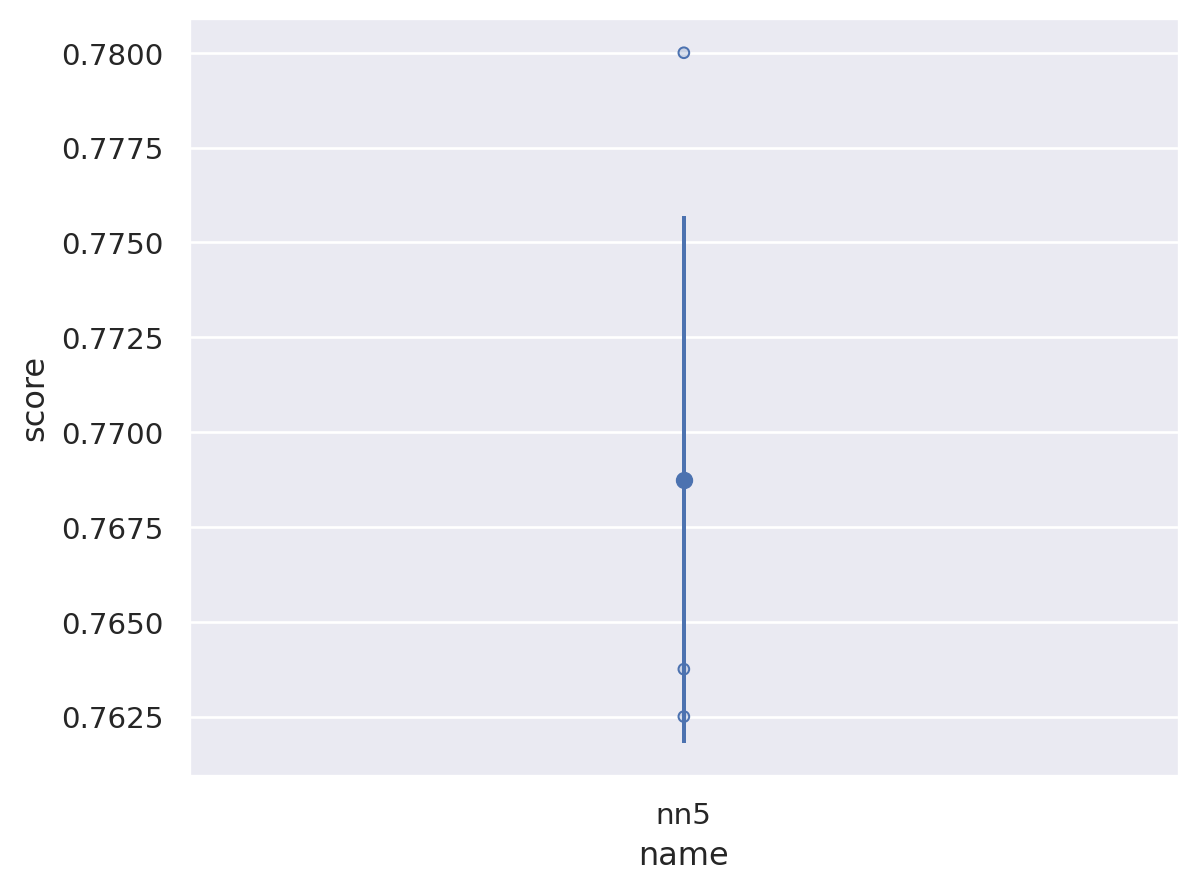

In [ ]:
(so.Plot(res, x='name', y='score')
  .add(so.Dot(), so.Agg())
  .add(so.Range(), so.Est(errorbar="sd"))
  .add(so.Dots())
)

Remember that the default cross validation is a stratified one wihout shuffling and thus that it can reproduced by:

In [ ]:
from sklearn.model_selection import StratifiedKFold

In [ ]:
cross_val_score(pipeline, X_train, y_train, cv=StratifiedKFold(n_splits=5), scoring='accuracy')

array([0.78   , 0.76375, 0.7625 , 0.76875, 0.76875])

**Question** What happens if one repeat the same experience 5 times using `shuffle=True, random_state=i` where $i$ is the number of the repetitions with

In [ ]:
res = pl.DataFrame()
for i in range(5):
  res = pl.concat([res,
                   pl.DataFrame({ 'name': 'nn5', 'rep': i,
                                  'fold': range(5),
                                 'score': cross_val_score(pipeline, X_train, y_train, cv=StratifiedKFold(n_splits=5,
                                                                                                         shuffle=True, random_state=i),
                                                           scoring='accuracy')})])

?

**Answer** We can observe quite a lot of variability on both the mean and the standard deviation

In [ ]:
res.drop('fold').group_by('rep', 'name').agg(pl.col('score').mean().alias('mean score'), pl.col('score').std().alias('score std'))

rep,name,mean score,score std
i32,str,f64,f64
2,"""nn5""",0.7715,0.011194
4,"""nn5""",0.76375,0.015
1,"""nn5""",0.771,0.005108
3,"""nn5""",0.76375,0.006555
0,"""nn5""",0.769,0.013532


As often, this can be grasped quickly with a good represenation:

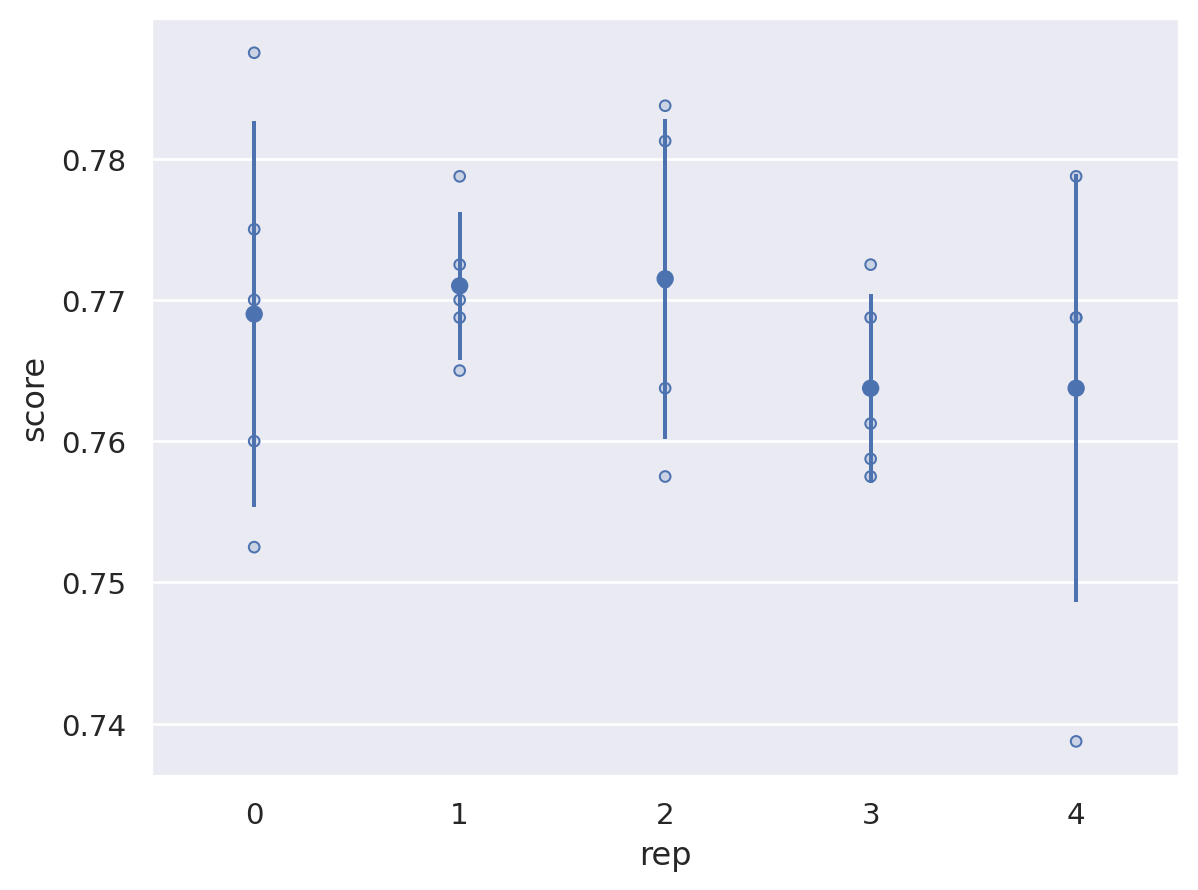

In [ ]:
(so.Plot(res, x='rep', y='score')
  .add(so.Dot(), so.Agg())
  .add(so.Range(), so.Est(errorbar="sd"))
  .add(so.Dots())
  .scale(x=so.Nominal())
)

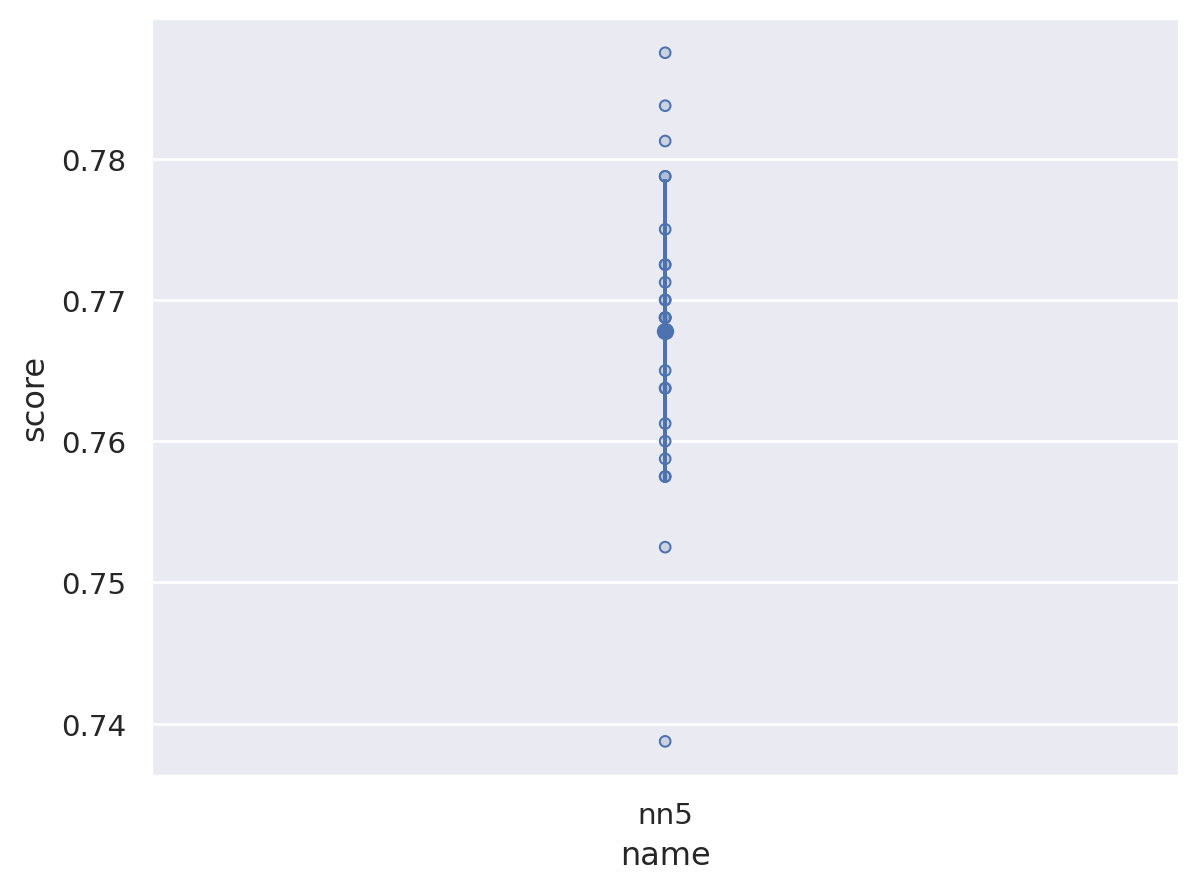

In [ ]:
(so.Plot(res, x='name', y='score')
  .add(so.Dot(), so.Agg())
  .add(so.Range(), so.Est(errorbar="sd"))
  .add(so.Dots())
)

**---**

**Question** Compare the scores between the nearest neighbor classifier and the logistic one.

In [ ]:
for i in range(5):
  res = pl.concat([res,
                   pl.DataFrame({ 'name': 'logistic', 'rep': i,
                                  'fold': range(5),
                                  'score': cross_val_score(pipeline_log, X_train, y_train, cv=StratifiedKFold(n_splits=5,
                                                                                                         shuffle=True, random_state=i),
                                                           scoring='accuracy')})])

**Answer**

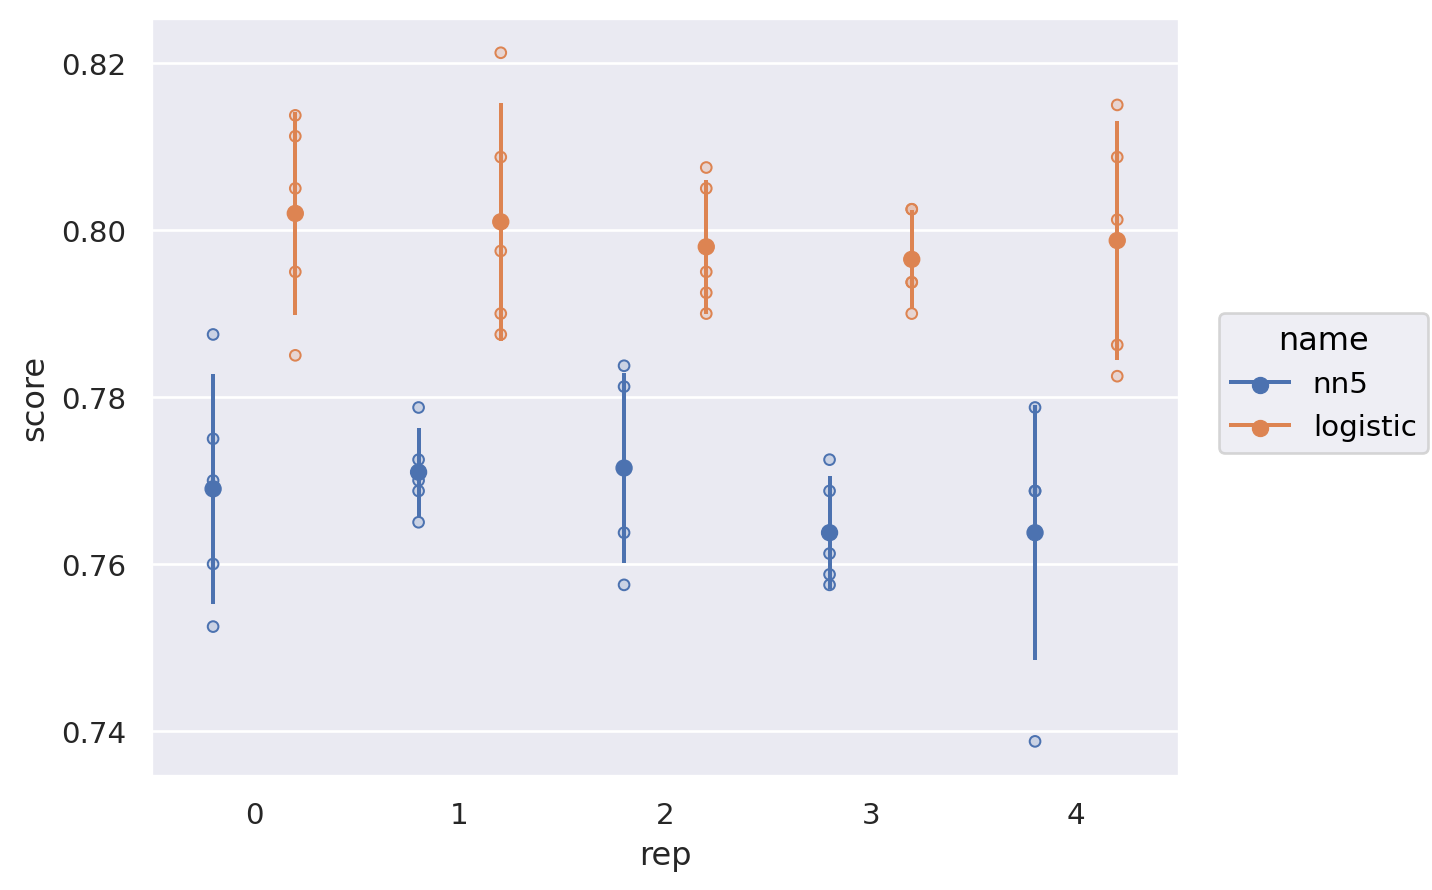

In [ ]:
(so.Plot(res, x='rep', y='score', color='name')
  .add(so.Dot(), so.Agg(), so.Dodge())
  .add(so.Range(), so.Est(errorbar="sd"), so.Dodge())
  .add(so.Dots(), so.Dodge())
  .scale(x=so.Nominal())
)

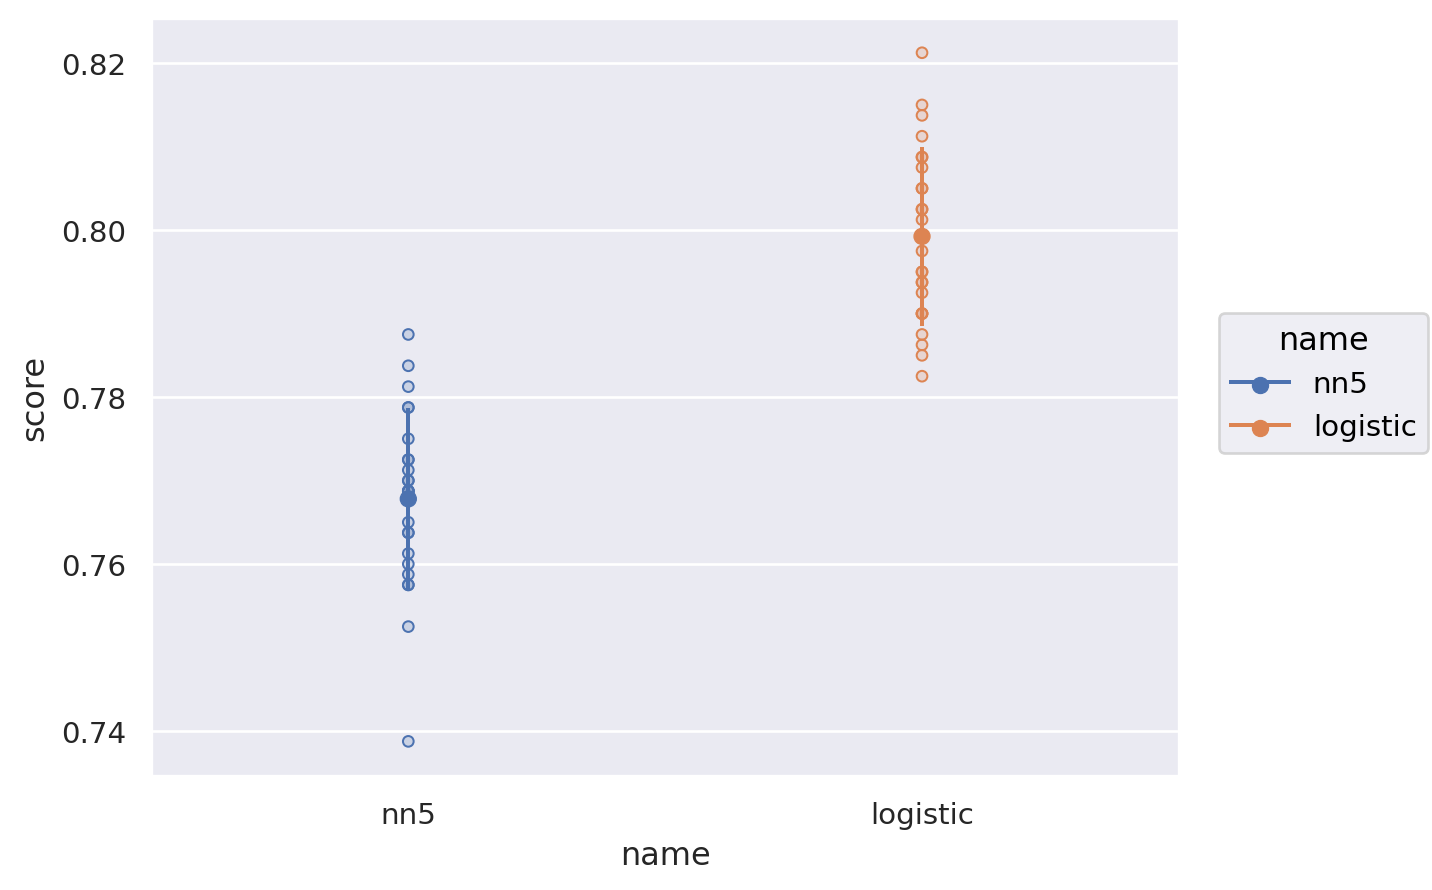

In [ ]:
(so.Plot(res, x='name', y='score', color='name')
  .add(so.Dot(), so.Agg())
  .add(so.Range(), so.Est(errorbar="sd"))
  .add(so.Dots())
)

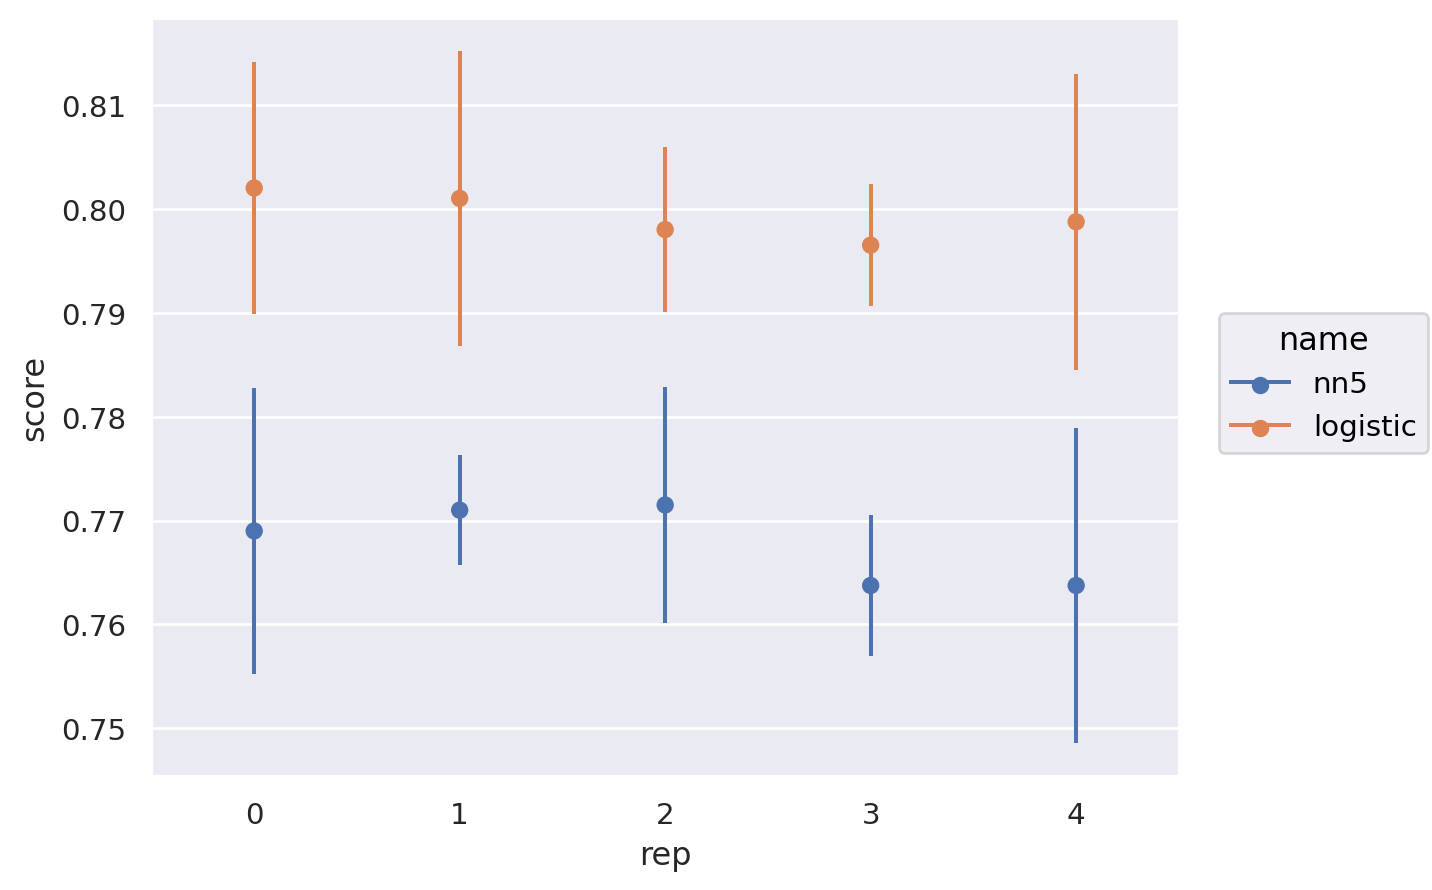

In [ ]:
(so.Plot(res, x='rep', y='score', color='name')
  .add(so.Dot(), so.Agg())
  .add(so.Range(), so.Est(errorbar="sd"))
  .scale(x=so.Nominal())
)

In [ ]:
diff = res.pivot(index=['rep', 'fold'], on='name').with_columns((pl.col('logistic')-pl.col('nn5')).alias('diff'))

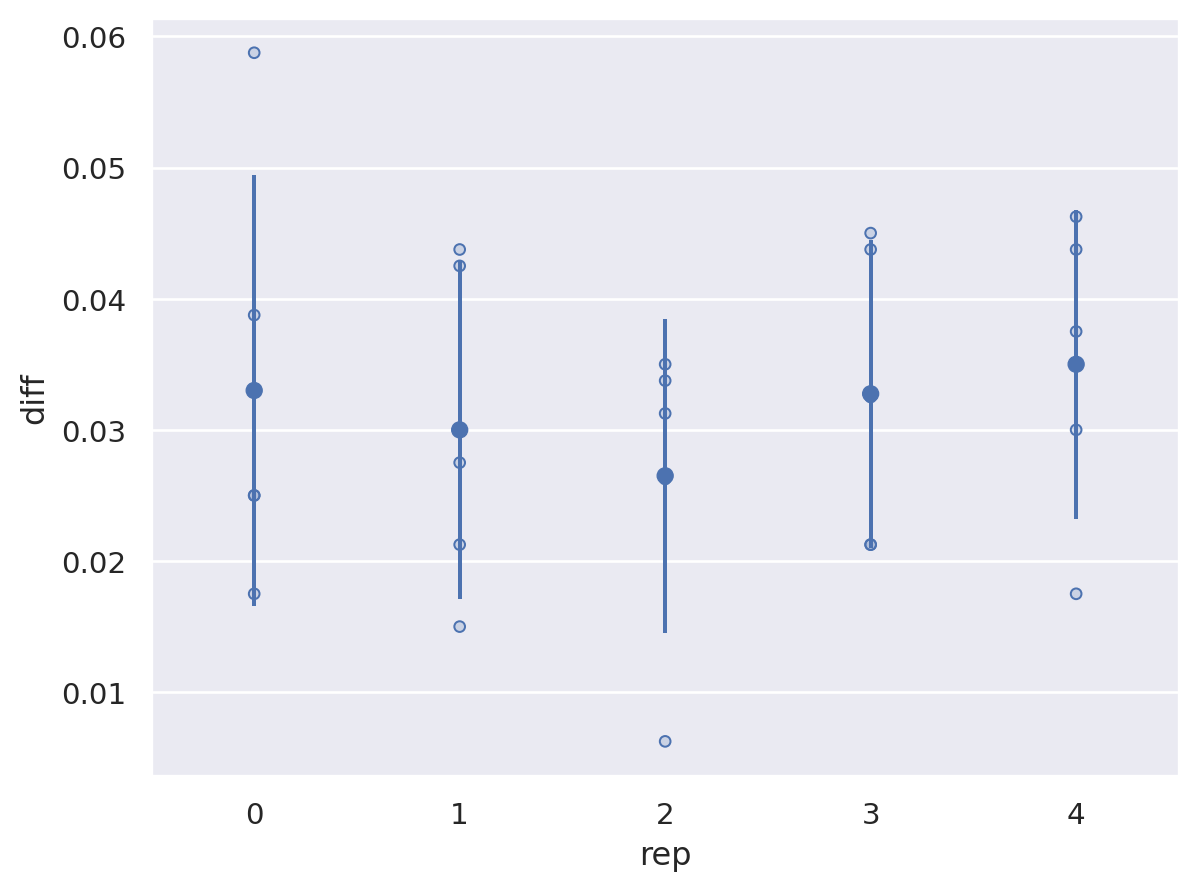

In [ ]:
(so.Plot(diff, x='rep', y='diff')
 .add(so.Dots())
 .add(so.Dot(),so.Agg())
 .add(so.Range(), so.Est(errorbar="sd"))
 .scale(x=so.Nominal())
)

**---**

So far we have used the standard deviation:

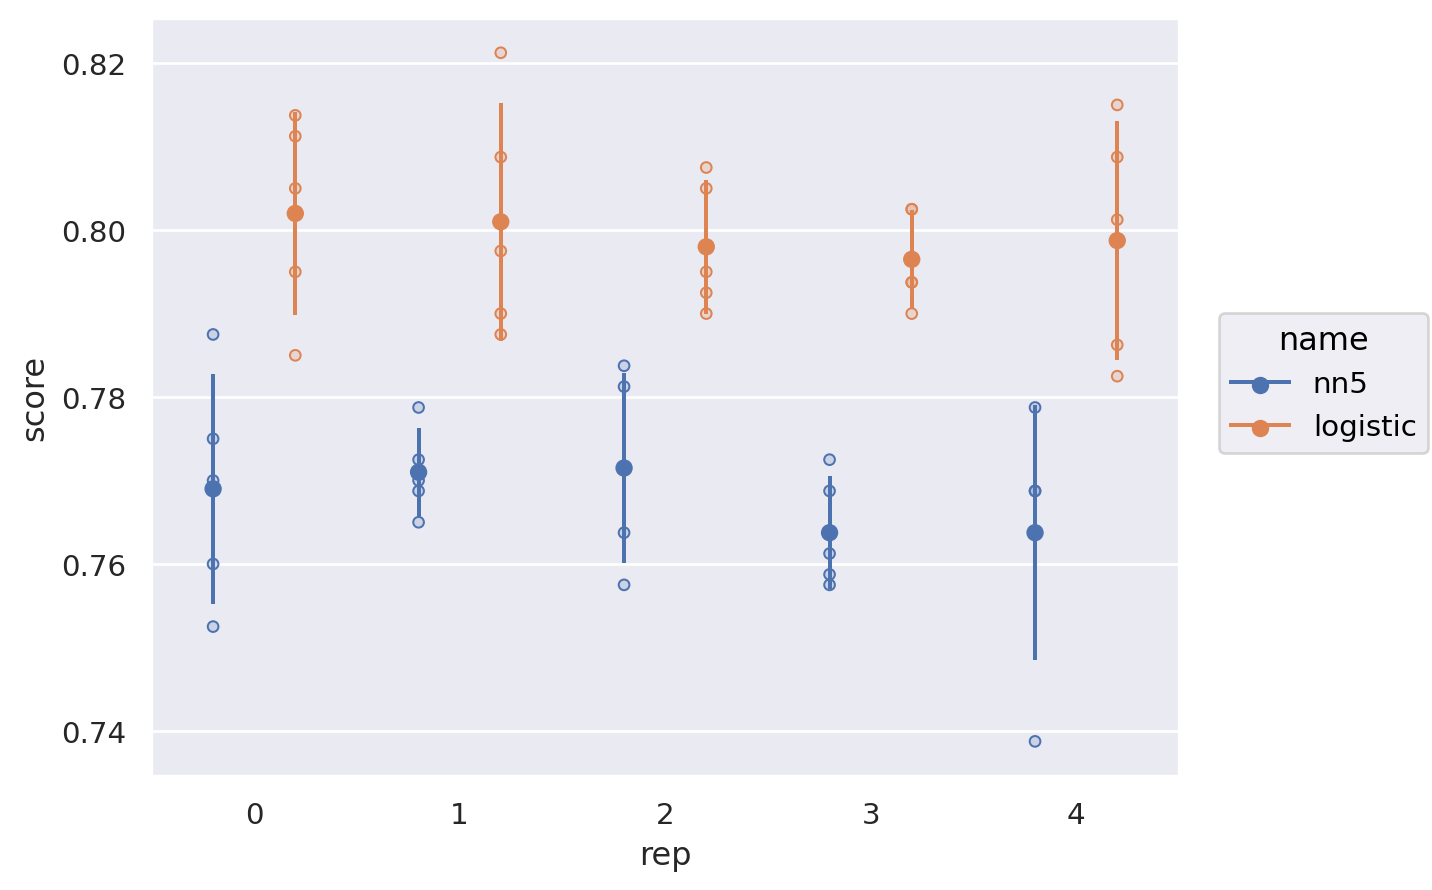

In [ ]:
(so.Plot(res, x='rep', y='score', color='name')
 .add(so.Dots(),so.Dodge())
 .add(so.Dot(),so.Agg(),so.Dodge())
 .add(so.Range(), so.Est(errorbar="sd"),so.Dodge())
 .scale(x=so.Nominal())
)

*but* we could also use the standard error (the standard deviation divided by the square root of the number of repetions):

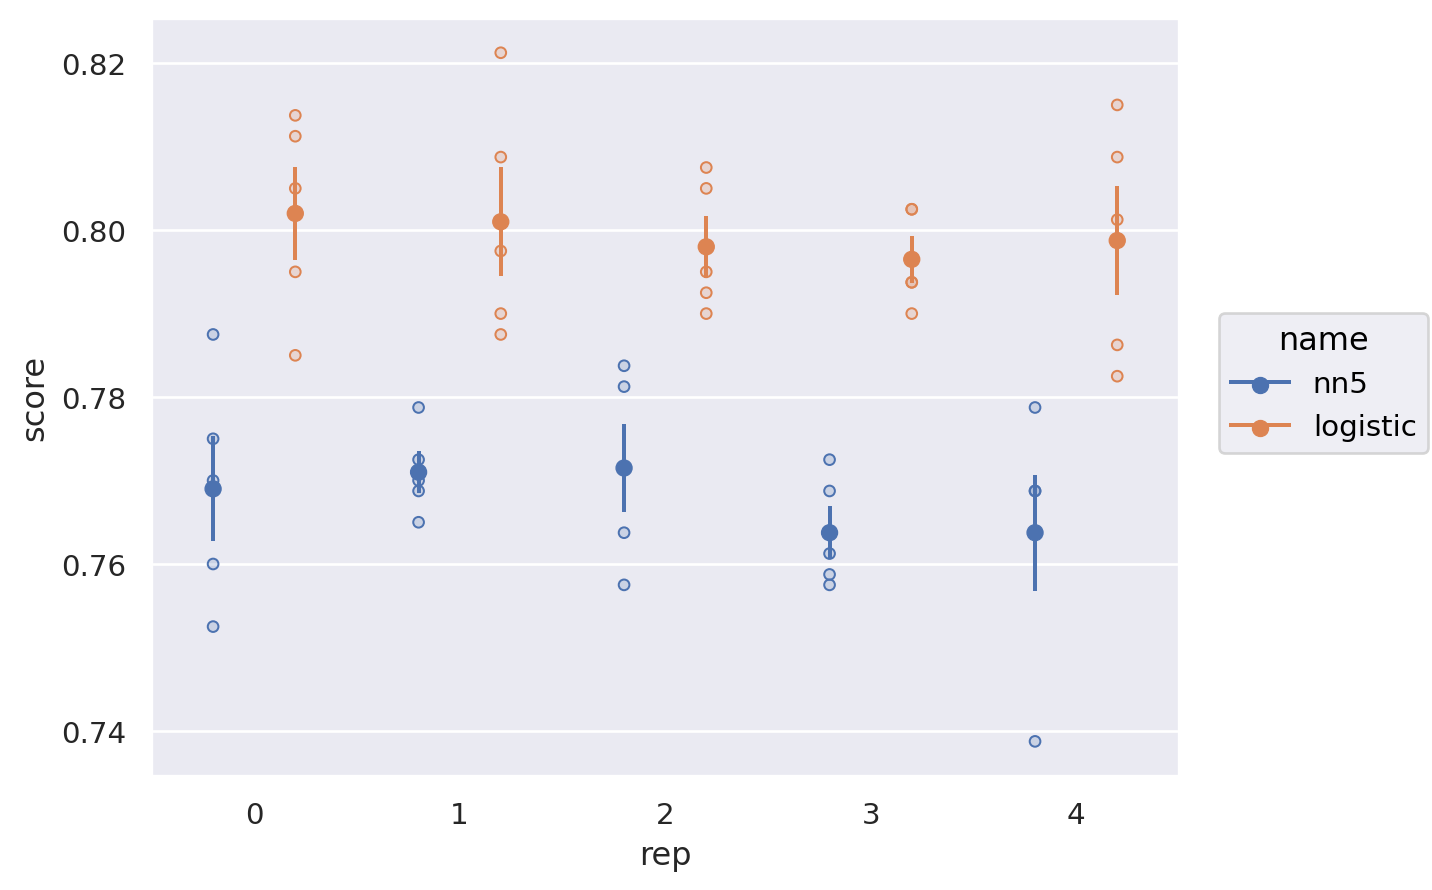

In [ ]:
(so.Plot(res, x='rep', y='score', color='name')
 .add(so.Dots(),so.Dodge())
 .add(so.Dot(),so.Agg(),so.Dodge())
 .add(so.Range(), so.Est(errorbar="se"),so.Dodge())
 .scale(x=so.Nominal())
)

**Question** What are the heuristics beyond those choices?

**Answer** For the first one, we are looking at the variability of the accuracy and producing a *confidence* interval for the actual accuracy. For the second one, we are looking at the variability of the estimate of the average accuracy. The second approach (using a Gaussian approximation) is more justified from the mathematical point of view (up to the dependency between the folds), while the first one takes into account the variability of the accuracies (a la Probably Approximately Correct), but use a non justified Gaussian approximation. Note that quantiles could also have been used for the first approach.

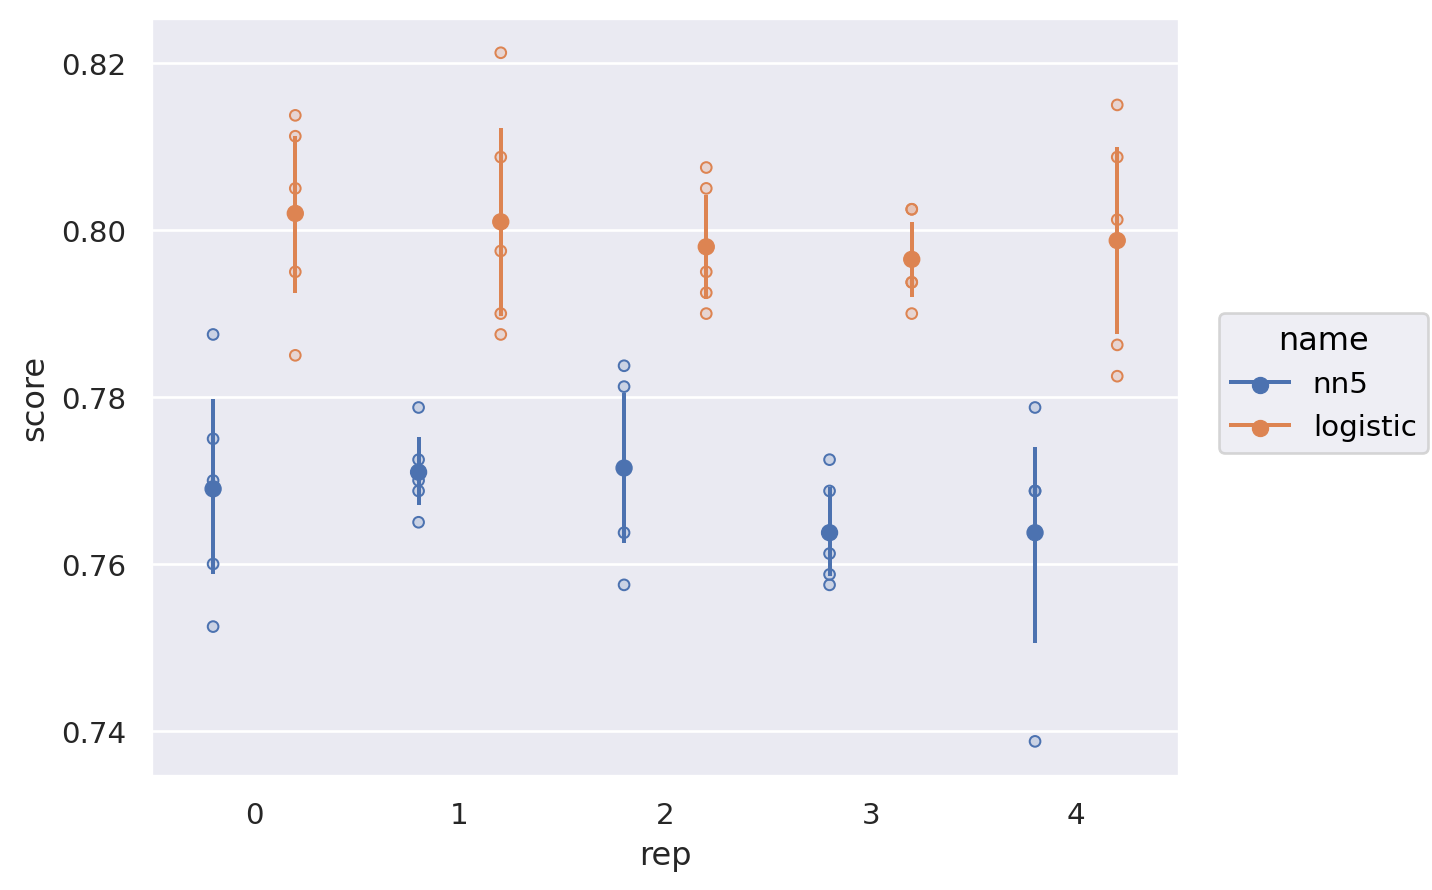

In [ ]:
(so.Plot(res, x='rep', y='score', color='name')
 .add(so.Dots(),so.Dodge())
 .add(so.Dot(),so.Agg(),so.Dodge())
 .add(so.Range(), so.Est(),so.Dodge())
 .scale(x=so.Nominal())
)

**---**

**Question** Find the "best" number of neighbors using cross validation. You can restrict yourself to the following values:

In [ ]:
n_neighbors_values = [3, 5, 7, 11, 15, 19, 25, 31, 37, 47, 57, 67, 90, 150, 300, 600]

Note that the best model could be the one with the larger average accuracy, the one with the larger lower confidence value of the accuracy ot its mean, or even the simpler model whose average could be as large as the best average accuracy.

**Answer**

In [ ]:
res = pl.DataFrame()

for n in n_neighbors_values:
  pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', KNeighborsClassifier(n_neighbors=n))]).set_output(transform="polars")
  res = pl.concat([res,
                   pl.DataFrame({ 'name': f'nn{n:03d}',
                                  'fold': range(5),
                                  'score': cross_val_score(pipeline, X_train, y_train, cv=StratifiedKFold(n_splits=5),
                                                           scoring='accuracy')})])

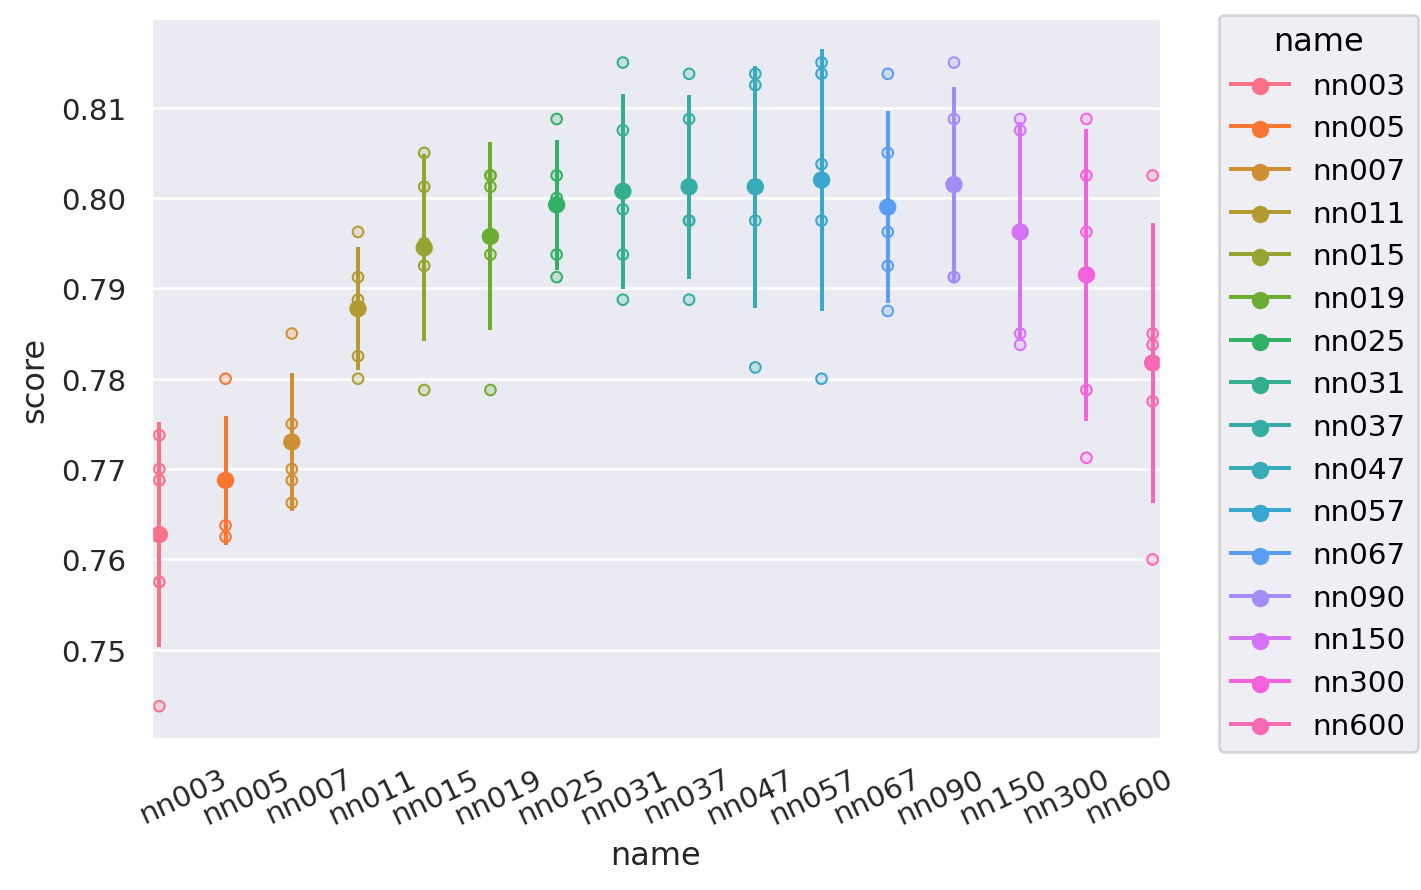

In [ ]:
p = (so.Plot(res, x='name', y='score', color='name')
 .add(so.Dots(),so.Dodge())
 .add(so.Dot(),so.Agg(),so.Dodge())
 .add(so.Range(), so.Est(errorbar="sd"),so.Dodge())
 .scale(x=so.Nominal())
).plot()
p._figure.axes[0].xaxis.set_tick_params(rotation=25)
p

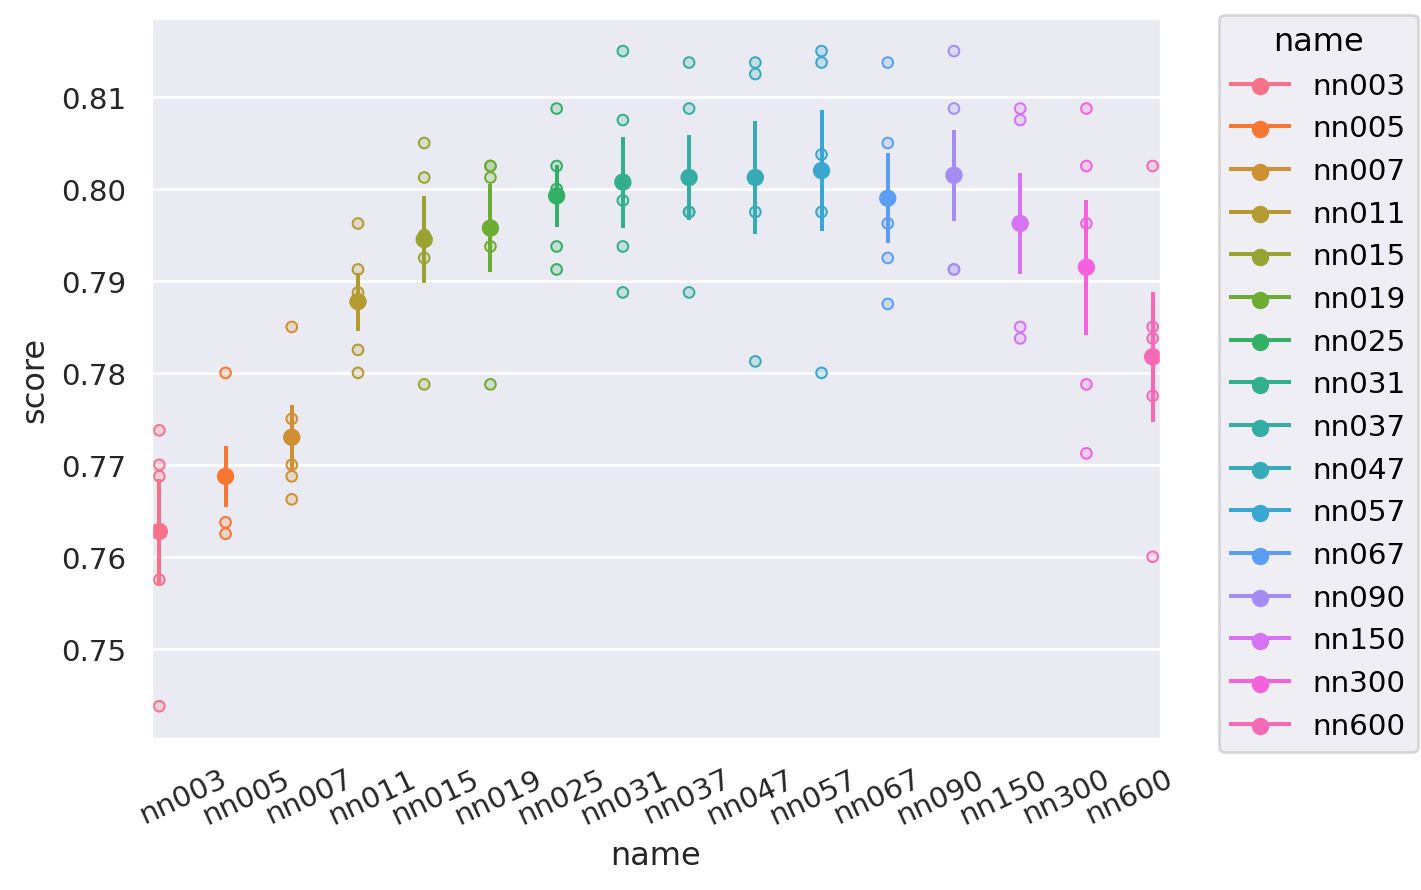

In [ ]:
p = (so.Plot(res, x='name', y='score', color='name')
 .add(so.Dots(),so.Dodge())
 .add(so.Dot(),so.Agg(),so.Dodge())
 .add(so.Range(), so.Est(errorbar="se"),so.Dodge())
 .scale(x=so.Nominal())
).plot()
p._figure.axes[0].xaxis.set_tick_params(rotation=25)
p

In [ ]:
scores = (res.group_by('name').agg(pl.col('score').mean().alias('mean'),
                         pl.col('score').std().alias('sd'),
                          pl.col('score').len().alias('n'))
 .with_columns((pl.col('mean')-pl.col('sd')).alias('lower_sd'),
               (pl.col('mean')+pl.col('sd')).alias('upper_sd'))
  .with_columns((pl.col('mean')-pl.col('sd')/pl.col('n').sqrt()).alias('lower_se'),
               (pl.col('mean')+pl.col('sd')/pl.col('n').sqrt()).alias('upper_se'))
)

In [ ]:
(scores
 .filter(pl.col('mean')==pl.col('mean').max())
 .sort('name')
)

name,mean,sd,n,lower_sd,upper_sd,lower_se,upper_se
str,f64,f64,u32,f64,f64,f64,f64
"""nn057""",0.802,0.014269,5,0.787731,0.816269,0.795619,0.808381


In [ ]:
(scores
 .filter(pl.col('lower_sd')==pl.col('lower_sd').max())
 .sort('name')
)

name,mean,sd,n,lower_sd,upper_sd,lower_se,upper_se
str,f64,f64,u32,f64,f64,f64,f64
"""nn025""",0.79925,0.006993,5,0.792257,0.806243,0.796123,0.802377


In [ ]:
(scores
 .filter(pl.col('lower_se')==pl.col('lower_se').max())
 .sort('name')
)

name,mean,sd,n,lower_sd,upper_sd,lower_se,upper_se
str,f64,f64,u32,f64,f64,f64,f64
"""nn037""",0.80125,0.009961,5,0.791289,0.811211,0.796795,0.805705


In [ ]:
(scores
 .filter(pl.col('upper_se')>=pl.col('mean').max())
 .sort('name', descending=True)
)

name,mean,sd,n,lower_sd,upper_sd,lower_se,upper_se
str,f64,f64,u32,f64,f64,f64,f64
"""nn090""",0.8015,0.010548,5,0.790952,0.812048,0.796783,0.806217
"""nn067""",0.799,0.010436,5,0.788564,0.809436,0.794333,0.803667
"""nn057""",0.802,0.014269,5,0.787731,0.816269,0.795619,0.808381
"""nn047""",0.80125,0.013199,5,0.788051,0.814449,0.795347,0.807153
"""nn037""",0.80125,0.009961,5,0.791289,0.811211,0.796795,0.805705
"""nn031""",0.80075,0.010555,5,0.790195,0.811305,0.79603,0.80547
"""nn025""",0.79925,0.006993,5,0.792257,0.806243,0.796123,0.802377


**---**

## Learning with weights and cost

Assume now that we know than in the realworld the proportion of `Risk`is $.02$, which is much smaller than we have in our dataset. We could try to adapt our process to take this information into account.

A first step is to define a new custom metric (and its corresponding scorer) to estimate the accuracy in the real world. This can be done as follows:

In [ ]:
real_prop = {'Risk': .02, 'No Risk': .98}
train_prop = {'Risk': 1/3, 'No Risk': 2/3}

In [ ]:
custom_weight = {'Risk': real_prop['Risk']/train_prop['Risk'], 'No Risk': real_prop['No Risk']/train_prop['No Risk']}

In [ ]:
def custom_metric(y_true, y_pred):
  loss = (custom_weight['Risk']*(y_true=='Risk')+custom_weight['No Risk']*(y_true=='No Risk')) *\
    (pl.Series(y_pred) != y_true)
  return(1-loss.mean())

In [ ]:
custom_scorer = sklearn.metrics.make_scorer(custom_metric)

If we use the Logistic regression (and refit it to be sure), we can compute its accuracy:

In [ ]:
pipeline_log.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
custom_scorer(pipeline_log, X_test, y_test)

0.88606

We verify easily that this accuracy is different from the one obtain with the usual metric:

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_scorer =  sklearn.metrics.make_scorer(accuracy_score)

In [ ]:
accuracy_scorer(pipeline_log, X_test, y_test)

0.793

**Question** Is this a good score?

**Answer** A score of $.88$ is really bad, as a dummy classifier predicting only `No Risk` will have an accuracy of $.98$.

**---**

A better predictor should be obtained if we use those weights during training.

In [ ]:
def compute_weights(y_true):
  return(custom_weight['Risk']*(y_true=='Risk')+custom_weight['No Risk']*(y_true=='No Risk'))

In [ ]:
from sklearn.base import clone
pipeline_log_weighted = clone(pipeline_log)

In [ ]:
pipeline_log_weighted.fit(X_train, y_train, classifier__sample_weight=compute_weights(y_train))

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
custom_scorer(pipeline_log_weighted, X_test, y_test)

0.98023

We are indeed much better than with the original predictor.

A second approach is to use the probability estimated in the dataset world and to modify the decision to take into account the proportions.

In [ ]:
import numpy as np
def custom_predict_from_proba(proba):
  decision = np.vstack([proba[:,0] *  custom_weight['No Risk'],
                  proba[:,1] *  custom_weight['Risk']])
  return(pl.Series(pipeline_log.classes_[decision.argmax(axis=0)]))

def custom_predict(pipeline, X_test):
  proba = pipeline.predict_proba(X_test)
  return(custom_predict_from_proba(proba))

In [ ]:
y_pred = custom_predict(pipeline_log, X_test)

In [ ]:
custom_metric(y_test, y_pred)

0.98074

which is very similar.

Note that to use a scorer function, one has to do a little hack:

In [ ]:
def custom_predict_from_single_proba(proba):
  proba=np.column_stack((1.0-proba, proba))
  return(custom_predict_from_proba(proba))

def custom_metric_from_proba(y_true, proba):
  y_pred = custom_predict_from_single_proba(proba)
  return(custom_metric(y_true, y_pred))

custom_scorer_from_proba = sklearn.metrics.make_scorer(custom_metric_from_proba, response_method="predict_proba")

In [ ]:
custom_scorer_from_proba(pipeline_log, X_test, y_test)

0.98074

**Question** Are those classifiers good?

**Answer** Not really, as their accuracies are very close from the one of the dummy classifier!

**---**

It turns out that the accuracy is probably not the best way to measure the quality of such a predictor. Indeed the cost of such a prediction depends on the predictio, the real outcome... and the amount of the loan.

A possible cost model could be:
- $5.0 + .5 \times \text{LoanAmount}$ if we predict `No Risk` and there was a `Risk` (default), as we may lose a lot of money to process those issues.
- $1.0 - .1 \times \text{LoanAmount}$ if we predict `No Risk` and there was a indeed `No Risk` (default), if we assume that the expected benefit is $.1 \times \text{LoanAmount}$ after an initial cost of $1$.
- $1$ if we predict `Risk`, as noting is going to happen after the refusal.

This could be encoded in the following metric:

In [ ]:
def compute_costs(LoanAmount):
  return({'Risk_No Risk': 5.0 + .6 * LoanAmount, 'No Risk_No Risk': 1.0 - .05 * LoanAmount,
          'Risk_Risk': 1.0, 'No Risk_Risk': 1.0})

In [ ]:
def custom_metric(y_true, y_pred, LoanAmount):
  costs = compute_costs(LoanAmount)
  y_pred = pl.Series(y_pred)
  loss = (y_true=='Risk') * custom_weight['Risk'] *\
                ((y_pred=='Risk') * costs['Risk_Risk'] + (y_pred=='No Risk') * costs['Risk_No Risk']) +\
         (y_true=='No Risk') * custom_weight['No Risk'] *\
                ((y_pred=='Risk') * costs['No Risk_Risk'] + (y_pred=='No Risk') * costs['No Risk_No Risk'])
  return(loss.mean())

In [ ]:
sklearn.set_config(enable_metadata_routing=True)
custom_scorer = sklearn.metrics.make_scorer(custom_metric, greater_is_better=False).set_score_request(LoanAmount=True)

This gives then

In [ ]:
LoanAmount = X['LoanAmount']

In [ ]:
X_train, X_test, y_train, y_test, LoanAmount_train, LoanAmount_test = train_test_split(X, y, LoanAmount, test_size=0.2, random_state=42)

In [ ]:
custom_scorer(pipeline_log, X_test, y_test, LoanAmount=LoanAmount_test)

87.1652445

Note that this value corresponds to the opposite of the expected average cost due to the use of the option `reater_is_better=False`. The expected average gain is thus positive here.

**Question** Can you find a better predictor for this metric?

**Answer**

We can use the reweighting approach:

In [ ]:
def compute_weights(y_true, LoanAmount):
  costs = compute_costs(LoanAmount)
  return(
      (y_true=='Risk') * custom_weight['Risk'] * (costs['Risk_No Risk']-costs['Risk_Risk'])
      + (y_true=='No Risk') * custom_weight['No Risk'] * (costs['No Risk_Risk']-costs['No Risk_No Risk'])
  )

In [ ]:
categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
numerical_transformer = Pipeline(steps=[
        ('scaler', StandardScaler().set_fit_request(sample_weight=True))
    ])

preprocessor = ColumnTransformer(
        transformers=[
            ('cat', categorical_transformer, categorical_features),
            ('num', numerical_transformer, numerical_columns)
        ],
        remainder='passthrough',
        force_int_remainder_cols=False
    )
pipeline_log_weighted = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', LogisticRegression().set_fit_request(sample_weight=True))]).set_output(transform="polars")

In [ ]:
pipeline_log_weighted.fit(X_train, y_train, sample_weight=compute_weights(y_train, LoanAmount_train))

/usr/local/lib/python3.12/dist-packages/sklearn/compose/_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
custom_scorer(pipeline_log_weighted, X_test, y_test, LoanAmount=LoanAmount_test)

95.140962

In [ ]:
def custom_predict_from_proba(proba, LoanAmount):
  classes_ = np.array(['No Risk', 'Risk'])
  costs = compute_costs(LoanAmount)
  decision = np.vstack([( proba[:, 0] * custom_weight['No Risk'] * costs['No Risk_No Risk'] + proba[:, 1] * custom_weight['Risk'] * costs['Risk_No Risk']),
                       ( proba[:, 0] * custom_weight['No Risk'] * costs['No Risk_Risk'] + proba[:, 1] * custom_weight['Risk'] * costs['Risk_Risk'])])
  return(pl.Series(classes_[decision.argmin(axis=0)]))

def custom_predict_from_single_proba(proba, LoanAmount):
  proba=np.column_stack((1.0-proba, proba))
  return(custom_predict_from_proba(proba, LoanAmount))

def custom_predict(pipeline, X_test, LoanAmount):
  proba = pipeline.predict_proba(X_test)
  return(custom_predict_from_proba(proba, LoanAmount))

In [ ]:
custom_metric(y_test, custom_predict(pipeline_log, X_test, LoanAmount_test), LoanAmount_test)

-97.28247300000001

In [ ]:
def custom_metric_from_proba(y_true, proba, LoanAmount):
  y_pred = custom_predict_from_single_proba(proba, LoanAmount)
  return(custom_metric(y_true, y_pred, LoanAmount))

custom_scorer_from_proba = sklearn.metrics.make_scorer(custom_metric_from_proba, response_method="predict_proba", greater_is_better=False).set_score_request(LoanAmount=True)

In [ ]:
custom_metric_from_proba(y_test, pipeline_log.predict_proba(X_test)[:,1].flatten(), LoanAmount_test)

-97.28247300000001

In [ ]:
custom_scorer_from_proba(pipeline_log, X_test, y_test, LoanAmount=LoanAmount_test)

97.28247300000001

**---**